# Original Gaussian experiment

Reproduce the original `GaussToy/GaussianBump/BalancedSync` experiment using copied observations and the original frozen learned map. The packaged NPZ and checkpoint files retain their original SHA-256 hashes. No endpoint clouds are regenerated.

In [1]:
from pathlib import Path
import uuid
import numpy as np
import torch
import matplotlib.pyplot as plt
import coati as ct
from coati.gaussian_reference import load_example, replay_reference, plot_reference

%matplotlib inline
example = load_example()
print("Primary snapshots:", [x.shape for x in example.data.primary])
print("Secondary snapshots:", [x.shape for x in example.data.secondary])

Primary snapshots: [(1000, 2), (2000, 2)]
Secondary snapshots: [(1000, 3), (2000, 3)]


## Replay the archived result

Load the original vector-field checkpoint and integrate it with COATI on the original visualization grid. The reported errors compare this replay with the original saved trajectory tensors.

Maximum replay errors: {'primary': 0.0, 'secondary': 1.1920928955078125e-07}


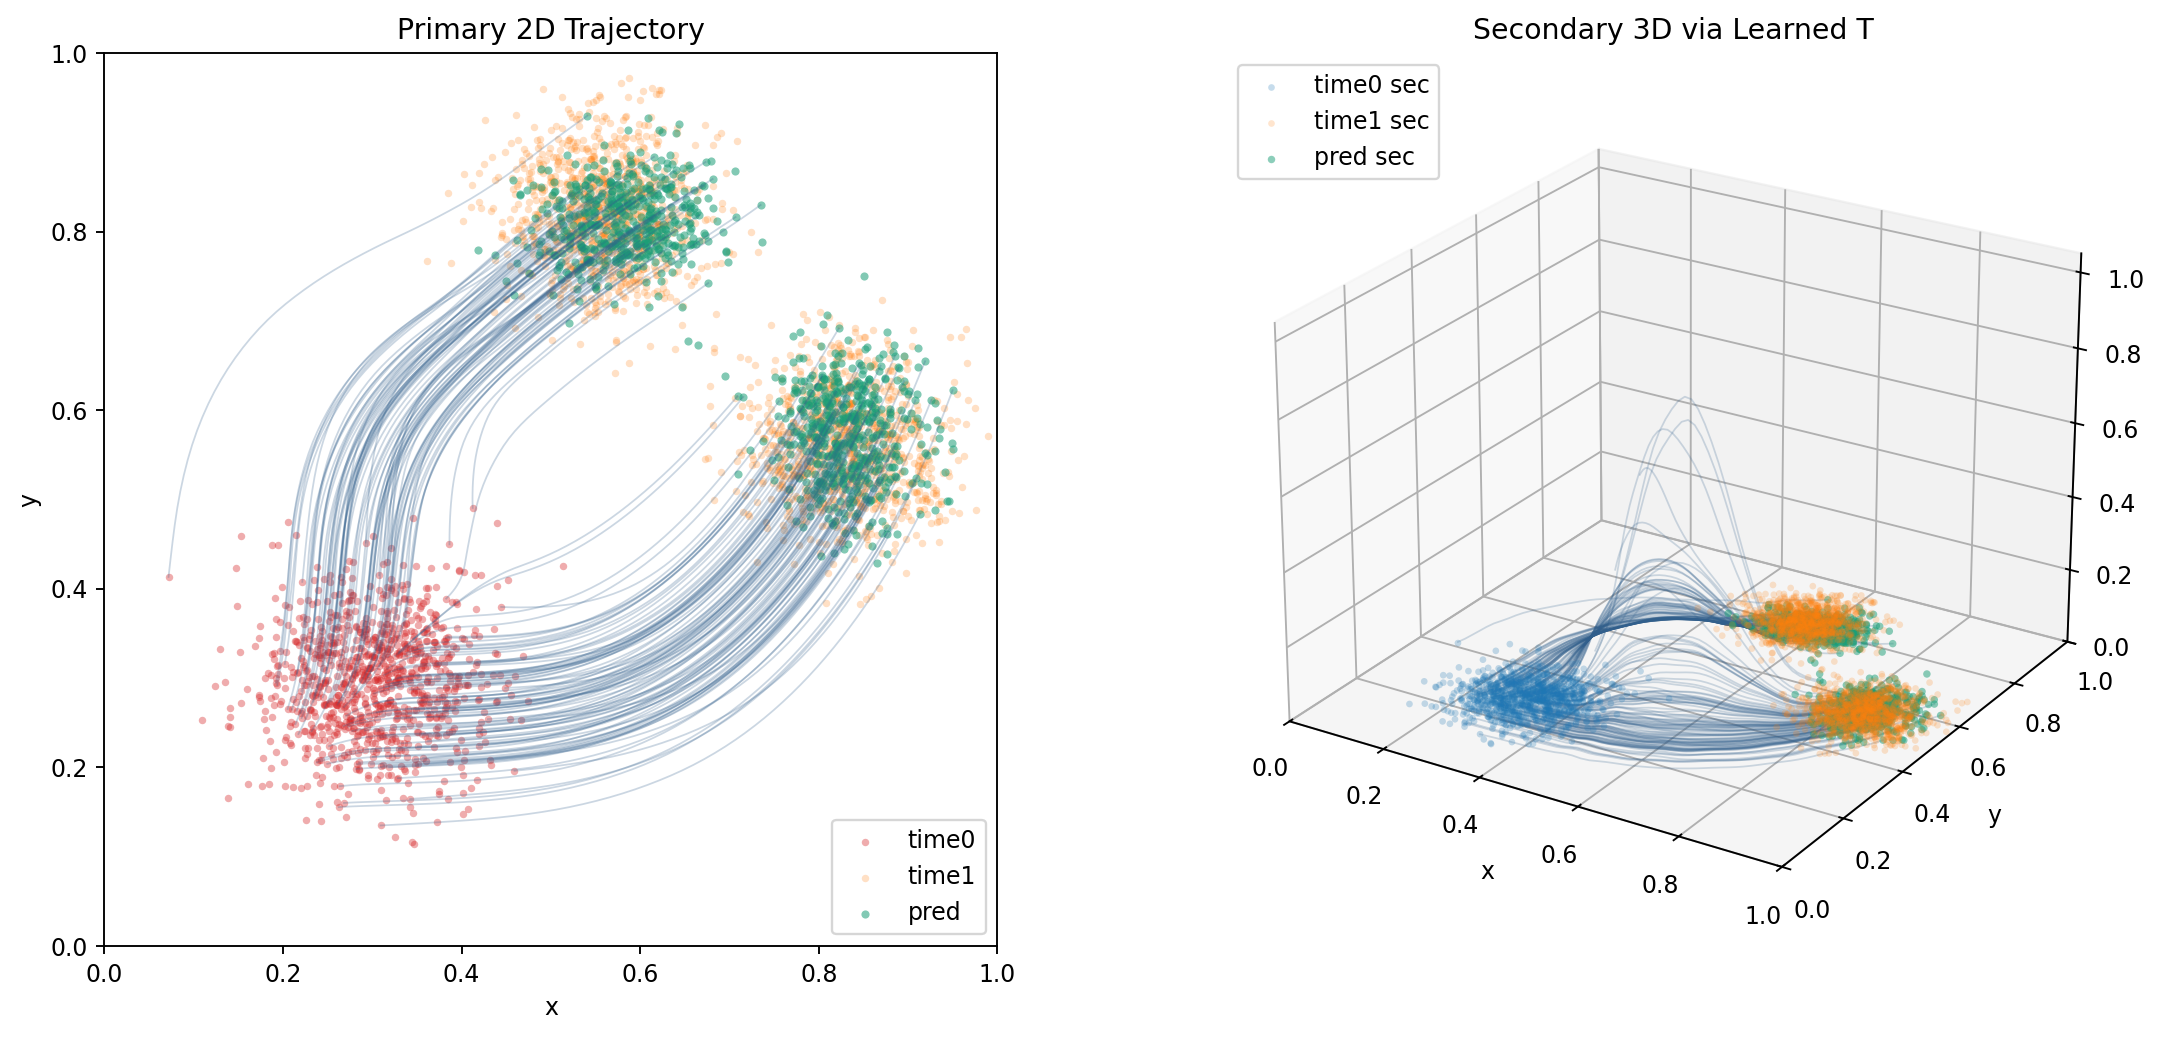

In [2]:
_, original_prediction, replay_error = replay_reference()
print("Maximum replay errors:", replay_error)
plot_reference(example, original_prediction)
plt.show()

## Train with the original data and settings

Use the same copied observations, frozen learned map and reference configuration, directly from scratch. Checkpoint replay reproduces the archived trajectory; refitting creates a new optimization run and need not reproduce every floating-point value of the historical run.

In [3]:
run_dir = Path("outputs") / ("gaussian-reference-" + uuid.uuid4().hex[:8])
result = ct.train_vector_field(
    example.data, example.config, T_model=example.mapping, output_dir=run_dir,
)
print("Model:", run_dir)

Model: outputs/gaussian-reference-7c416252


## Plot the new fit

Use the original integration method, time grid, seeded path selection and plotting layout.

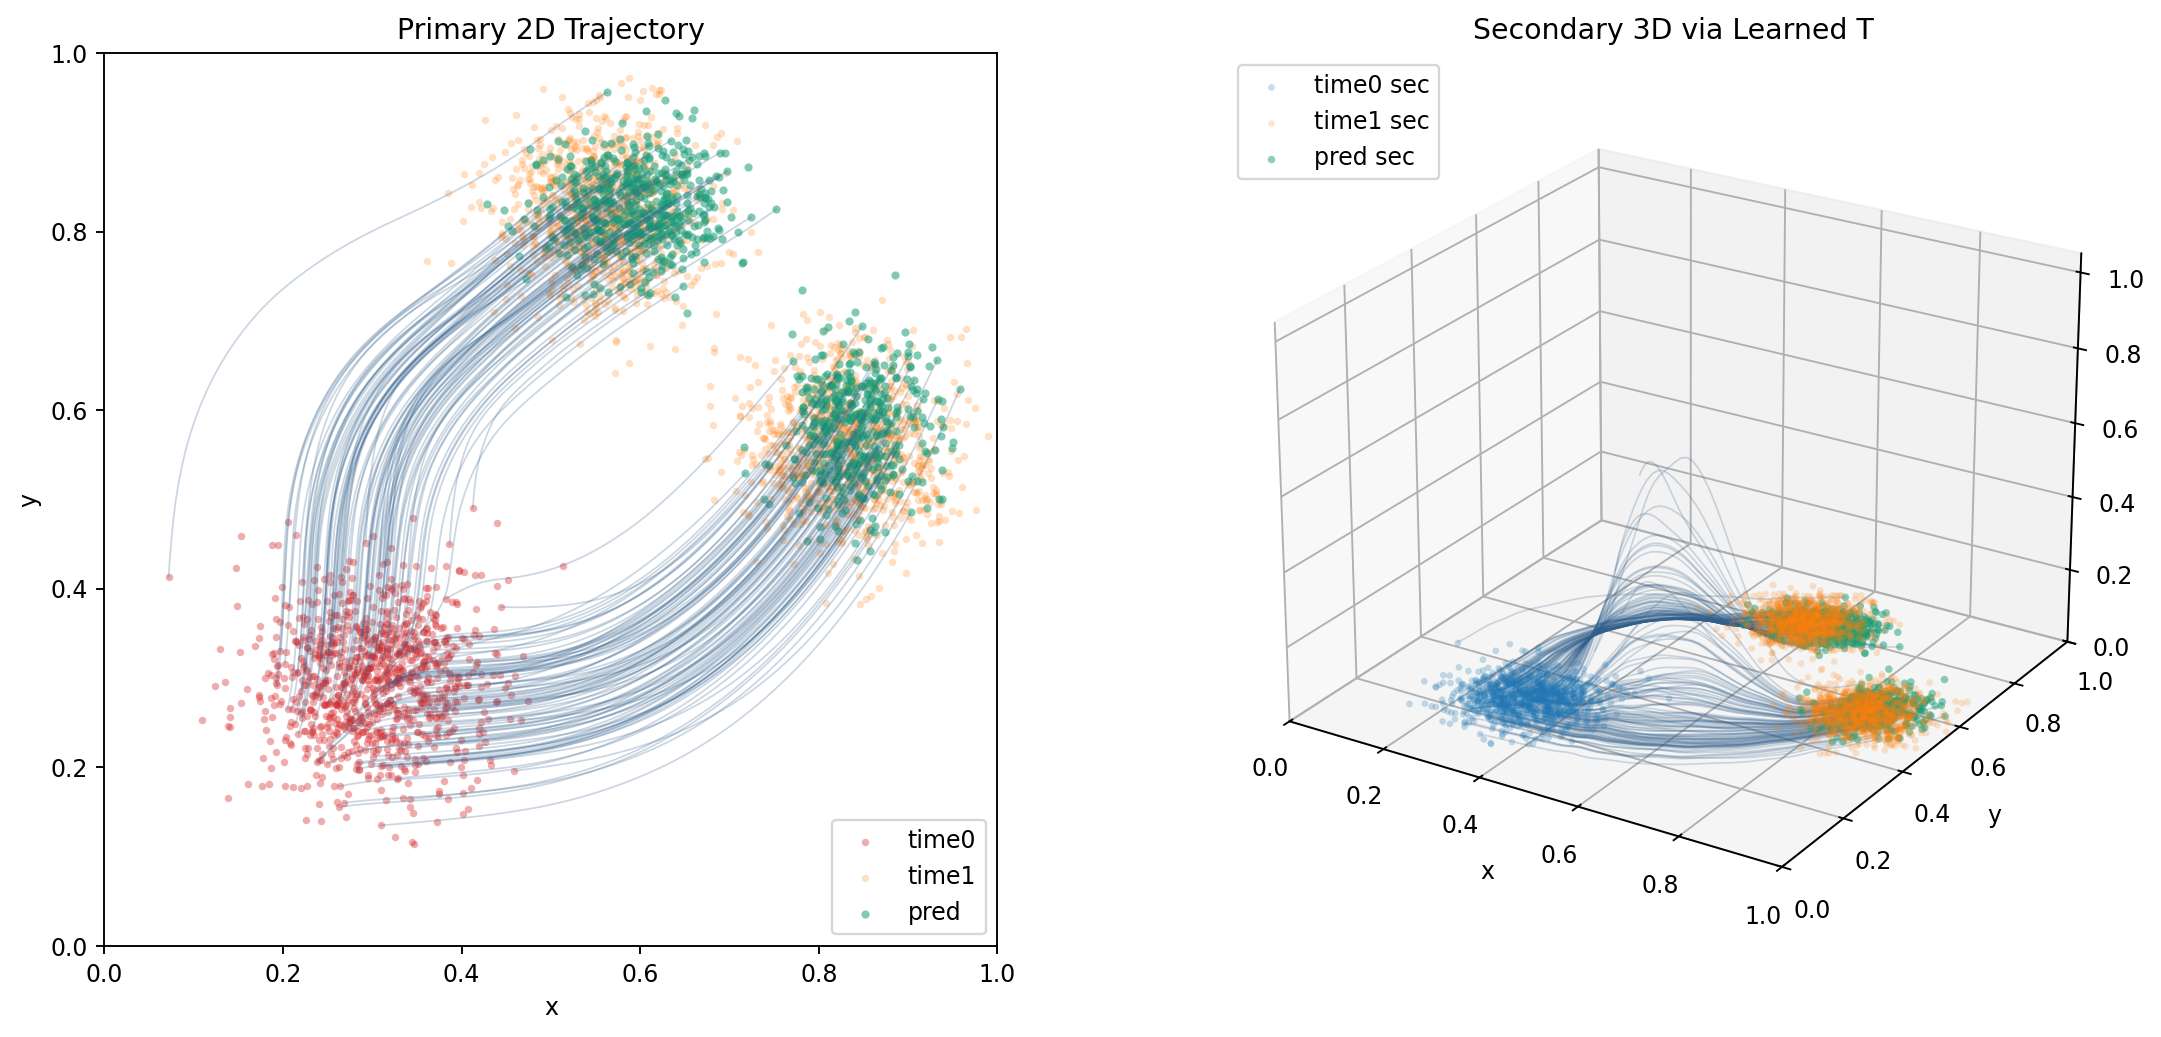

In [4]:
prediction = result.predict_trajectory(
    times=example.times, method=example.settings["prediction"]["method"],
)
with torch.no_grad():
    prediction["secondary"] = example.mapping(torch.tensor(prediction["primary"])).numpy()
plot_reference(example, prediction)
plt.show()

## Check the difference from the archived run

These arraywise errors describe reproducibility relative to the saved checkpoint, rather than biological or distributional accuracy.

In [5]:
for space in ("primary", "secondary"):
    delta = prediction[space] - original_prediction[space]
    print(space, "maximum difference:", float(np.abs(delta).max()),
          "RMSE:", float(np.sqrt(np.mean(delta ** 2))))

primary maximum difference: 0.35370585322380066 RMSE: 0.04401407390832901
secondary maximum difference: 0.6980593204498291 RMSE: 0.04108712449669838


Run the same experiment from Python:

```bash
python examples/run_gaussian_reference.py --output outputs/gaussian-reference
```

Replay the original checkpoint without refitting:

```bash
python examples/run_gaussian_reference.py --output outputs/gaussian-replay --replay
```

The separately adjusted [sync comparison](01_gaussian.ipynb) remains available.